# Machine Learning-Based Decoding for Planar Surface Codes

- **Author**: Théo HUET
- **Date**: 05/11/2026-09/11/2026

In [49]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc

This notebook builds directly upon our previous work, ["Introduction to the Surface Code"](https://github.com/TheoHUETQC/surface-code/blob/main/surface_code_introduction.ipynb), where we implemented a distance-3 ($d=3$) planar surface code using Qiskit and a classical Look-up Table decoder.

While a Look-up Table (LUT) is effective for single-qubit errors ($weight = 1$), it suffers from two major limitations:
1. **Exponential Scaling:** As the code distance $d$ increases, the number of possible syndromes grows exponentially, making static lookup tables unfeasible.
2. **Multiple Errors (Weight $> 1$):** LUTs struggle to handle overlapping or higher-weight errors without drastically expanding in complexity.

So we're going to use some code from this notebook without explaining it, it allows us to obtain the syndromes and the quantum circuit.

In [50]:
LOOKUP_TABLE = {
    # Format: ('Syndrome_X', 'Syndrome_Z'): [('Gate', Qubit_idx)]
    ('0000', '0000'): [],

    # X Errors (detected by the Z syndrome)
    ('0000', '0001'): [('X', 0)],
    ('0000', '0101'): [('X', 1)],
    ('0000', '0100'): [('X', 2)],
    #('0000', '0001'): [('X', 3)],
    ('0000', '0011'): [('X', 4)],
    ('0000', '0010'): [('X', 5)],
    ('0000', '1000'): [('X', 6)],
    ('0000', '1010'): [('X', 7)],
    #('0000', '0010'): [('X', 8)],

    # Z Errors (detected by the X syndrome)
    ('0100', '0000'): [('Z', 0)],
    ('0001', '0000'): [('Z', 1)],
    #('0001', '0000'): [('Z', 2)],
    ('0110', '0000'): [('Z', 3)],
    ('0011', '0000'): [('Z', 4)],
    ('1001', '0000'): [('Z', 5)],
    ('0010', '0000'): [('Z', 6)],
    #('0010', '0000'): [('Z', 7)],
    ('1000', '0000'): [('Z', 8)],

    # Y Errors (detected by both syndromes)
    ('0100', '0001'): [('X', 0), ('Z', 0)],
    ('0001', '0101'): [('X', 1), ('Z', 1)],
    ('0001', '0100'): [('X', 2), ('Z', 2)],
    ('0110', '0001'): [('X', 3), ('Z', 3)],
    ('0011', '0011'): [('X', 4), ('Z', 4)],
    ('1001', '0010'): [('X', 5), ('Z', 5)],
    ('0010', '1000'): [('X', 6), ('Z', 6)],
    ('0010', '1010'): [('X', 7), ('Z', 7)],
    ('1000', '0010'): [('X', 8), ('Z', 8)],
}

In [51]:
# from surface_code_introduction.ipynb
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

d = 3
nbr_logical_qubits = 1
nbr_data_qubits = d * d
nbr_ancilla_qubits = nbr_data_qubits - nbr_logical_qubits
nbr_ancilla_x = nbr_ancilla_qubits // 2
nbr_ancilla_z = nbr_ancilla_qubits - nbr_ancilla_x

def init_registers():
  q_data = QuantumRegister(nbr_data_qubits, name="data")
  q_anc_z = QuantumRegister(nbr_ancilla_z, name="ancilla_z")
  q_anc_x = QuantumRegister(nbr_ancilla_x, name="ancilla_x")
  c_syndrome_z = ClassicalRegister(nbr_ancilla_z, name="syndrome_z")
  c_syndrome_x = ClassicalRegister(nbr_ancilla_x, name="syndrome_x")
  return q_data, q_anc_z, q_anc_x, c_syndrome_z, c_syndrome_x

def stabilizer_circuit(qc, q_data, q_anc_z, q_anc_x, c_syndrome_z, c_syndrome_x):
  map_Z = {0: [0,1,3,4], 1: [4,5,7,8], 2: [1,2], 3: [6,7]}
  qc.barrier(label="Z-Stabilizer")
  for anc_Z_idx in range(nbr_ancilla_z):
    for data_idx in map_Z[anc_Z_idx]:
      qc.cx(q_data[data_idx], q_anc_z[anc_Z_idx])

  map_X = {0: [1,2,4,5], 1: [3,4,6,7], 2: [0,3], 3: [5,8]}
  qc.barrier(label="X-Stabilizer")
  for anc_X_idx in range(nbr_ancilla_x):
    qc.h(q_anc_x[anc_X_idx])
    for data_idx in map_X[anc_X_idx]:
      qc.cx(q_anc_x[anc_X_idx], q_data[data_idx])
    qc.h(q_anc_x[anc_X_idx])

  qc.barrier(label="Measurement")
  qc.measure(q_anc_z, c_syndrome_z)
  qc.measure(q_anc_x, c_syndrome_x)
  return qc

def build_surface_code_circuit(q_data, errors_to_inject=[], init_basis='Z'):
  q_anc_z, q_anc_x, c_syndrome_z, c_syndrome_x = init_registers()[1:]
  qc = QuantumCircuit(q_data, q_anc_z, q_anc_x, c_syndrome_z, c_syndrome_x, name="stabilizer_circuit")

  if init_basis == 'X':
    qc.barrier(label="State Prep")
    qc.h(q_data)

  qc.barrier(label="Error Injection")
  for error in errors_to_inject:
    if error[0] == 'X':
      qc.x(q_data[error[1]])
    elif error[0] == 'Z':
      qc.z(q_data[error[1]])

  qc = stabilizer_cluster_qc = stabilizer_circuit(qc, q_data, q_anc_z, q_anc_x, c_syndrome_z, c_syndrome_x)
  return qc

def simulate_surface_code(q_data, errors_to_inject=[], shots=100, init_basis='Z'):
  from qiskit_aer import AerSimulator
  from qiskit import transpile
  qc = build_surface_code_circuit(q_data, errors_to_inject, init_basis)
  simulator = AerSimulator()
  compiled_circuit = transpile(qc, simulator)
  job = simulator.run(compiled_circuit, shots=shots)
  counts = job.result().get_counts()
  return counts, qc

def recover_error_related_syndrome(q_data, errors_to_inject, shots=100):
  counts_Z, qc = simulate_surface_code(q_data, errors_to_inject, shots, init_basis='Z')
  most_common_z = max(counts_Z, key=counts_Z.get).split(" ")[1]
  counts_X, _ = simulate_surface_code(q_data, errors_to_inject, shots, init_basis='X')
  most_common_x = max(counts_X, key=counts_X.get).split(" ")[0]
  syndrome_x_str = most_common_x
  syndrome_z_str = most_common_z
  return syndrome_x_str, syndrome_z_str

### The Machine Learning Solution
To overcome these limitations, this project implements a **Neural Network Decoder using PyTorch**. Instead of hardcoding a static table, we will train a Multi-Layer Perceptron (MLP) to learn the non-linear mapping between error syndromes $(S_X, S_Z)$ and the optimal physical corrections.

### Objectives of this Notebook:
1. **Dataset Generation:** Automatically generate synthetic error-syndrome pairs using our Qiskit surface code simulation pipeline.
2. **PyTorch Architecture:** Build a classification neural network tailored for quantum error correction.
3. **Training & Evaluation:** Train the model, evaluate its accuracy, and compare its flexibility against the traditional Look-up Table approach.

### Understanding Error Weight
The **weight** of a Pauli error corresponds to the number of physical qubits simultaneously affected by a non-trivial error operator ($X$, $Y$, or $Z$).
- **Weight-1 errors** affect a single qubit (e.g., `[('X', 1)]` or a single $Y$ error on qubit 1). For a distance $d=3$ surface code, weight-1 errors are fully correctable.
- **Weight-2 errors** affect two distinct qubits simultaneously (e.g., `[('X', 1), ('Z', 4)]`). For a distance $d=3$ code, the code's correction capacity ($\lfloor(d-1)/2\rfloor = 1$) is exceeded, meaning weight-2 errors typically lead to uncorrectable logical failures.

In [52]:
def generate_possible_errors(weight=1):
  def get_pauli_opts(q):
    return [
      [('X', q)],                  # X
      [('Z', q)],                  # Z
      [('X', q), ('Z', q)]         # Y
      ]

  possible_errors = []
  nbr_qubits = 9
  qubits = range(nbr_qubits)

  for q in qubits: # error with weight == 1
    for opt in get_pauli_opts(q):
      possible_errors.append(opt)

  possible_errors.append([]) # Identity error

  if weight == 1:
    return possible_errors

  elif weight == 2:
   for q1 in qubits:
      for q2 in range(q1 + 1, nbr_qubits):
        for opt1 in get_pauli_opts(q1):
          for opt2 in get_pauli_opts(q2):
            possible_errors.append(opt1 + opt2)

  else:
    raise ValueError("Weight must be 1 or 2")
  return possible_errors

---

# 1. Dataset

In [53]:
import numpy as np
import torch

def generate_dataset_from_errors(num_samples=1000, weight=1):
  X_data = [] # Will contain the syndromes as binary vectors (4+4 bits total)
  y_data = [] # Will contain the index of the corresponding error in 'possible_errors'

  q_data, _, _, _, _ = init_registers()

  possible_errors = generate_possible_errors(weight=weight)

  for i in range(num_samples):
    if i % (num_samples*0.1) == 0:
      print(f"Generating sample {i}/{num_samples}")

    err_idx = np.random.randint(0, len(possible_errors))
    error_to_inject = possible_errors[err_idx]

    s_x, s_z = recover_error_related_syndrome(q_data, errors_to_inject=error_to_inject, shots=50)

    # Convert binary strings to lists of integers (e.g., '0011' -> [0, 0, 1, 1])
    vector = [int(bit) for bit in s_x + s_z]

    X_data.append(vector)
    y_data.append(err_idx)

  return torch.tensor(X_data, dtype=torch.float32), torch.tensor(y_data, dtype=torch.long)
  #return np.array(X_data, dtype=np.float32), np.array(y_data, dtype=np.int64)

---

# 2. Preprocessing

`TensorDataset` is a container that pairs your input data $X$ with your labels $y$, row by row.

`DataLoader` is a PyTorch tool for managing training in mini-batches. It takes your `TensorDataset` and automatically handles the following:

- Shuffling the data at each epoch (`shuffle=True`), which is crucial to prevent the model from learning the order of the examples.
- Splitting your dataset into fixed-size batches (e.g., `batch_size=64`).

In [54]:
from torch.utils.data import TensorDataset, DataLoader

def preprocess_dataset(X_tensor, y_tensor):
  dataset = TensorDataset(X_tensor, y_tensor)
  dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
  return dataloader

In [55]:
def generate_torch_dataset(num_samples=1000, weight=1):
  X_tensor, y_tensor = generate_dataset_from_errors(num_samples=num_samples, weight=weight)
  print("Dataset Size:", X_tensor.shape)
  return preprocess_dataset(X_tensor, y_tensor)

---

# 3. model building

In [56]:
import torch.nn as nn
import torch.nn.functional as F

class SurfaceCodeDecoderMLP(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=64, output_dim=28):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)

---

# 4. model training

## 4.1 optimization

In [57]:
import torch.optim as optim

def init_training(model):
  criterion = nn.CrossEntropyLoss() # opti for multi-classes classification
  optimizer = optim.Adam(model.parameters(), lr=0.005)
  return criterion, optimizer

---

## 4.2 Training Loop

In [58]:
def training(model, dataloader, num_epochs=15):
  criterion, optimizer = init_training(model)
  model.train()

  print("Start of model training")
  for epoch in range(num_epochs):
    total_loss = 0
    correct_predictions = 0
    total_samples = 0

    for batch_X, batch_y in dataloader:
      optimizer.zero_grad()
      outputs = model(batch_X)
      loss = criterion(outputs, batch_y)
      loss.backward()
      optimizer.step()

      # loss
      total_loss += loss.item() * batch_X.size(0)

      # accuracy
      _, predicted = torch.max(outputs, 1)
      correct_predictions += (predicted == batch_y).sum().item()

      total_samples += batch_y.size(0)

    epoch_loss = total_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc * 100:.2f}%")

  print("Complete")
  return model

---

# 5. Model 1 based on Weight 1

## 5.1 init model

In [59]:
possible_errors_1 = generate_possible_errors(weight=1)
num_classes_1 = len(possible_errors_1)

print("Number of possible errors:", num_classes_1)

Number of possible errors: 28


There are 28 possible (different) errors, so in a dataset of 2,500 samples, that would mean the same error occurs 90 times on average, which would be the minimum for us.

We can therefore use a dataset of 10,000 samples, which would result in the same error occurring 358 times.

Since the datasets we'll need are large and take a long time to generate using Qiskit, we'll save our datasets just once. They'll be stored in a "dataset" file on GitHub, which means we won't have to wait 20 minutes for a dataset, we'll just need to load it.

Otherwise, we could have generated our datasets by synthetically deriving syndromes based on errors, but the goal here is to be able to apply machine learning to more complex cases later on, such as weight 2 or higher, if that works, which require much larger lookup tables.

In [60]:
from torch.utils.data import DataLoader

def save_dataset(data, name):
  torch.save(data.dataset, name)
  print(f"Dataset successfully saved to {name}")

def load_dataset(samples, weight):
  name = f'datasets/surface_code_samples_{samples}_error_weight_{weight}.pt'
  try:
    loaded_dataset = torch.load(name, weights_only=False)
    print(f"Dataset successfully loaded from {name}")
    return DataLoader(loaded_dataset, batch_size=64, shuffle=True)
  except FileNotFoundError:
    print(f"Dataset not found. Generating new dataset...")
    data = generate_torch_dataset(num_samples=samples, weight=weight)
    save_dataset(data, name)
  return data

In [61]:
data_train_1 = load_dataset(samples=10000, weight=1)

Dataset successfully loaded from datasets/surface_code_samples_10000_error_weight_1.pt


In [62]:
model_1 = SurfaceCodeDecoderMLP(input_dim=8, hidden_dim=128, output_dim=num_classes_1)

In [63]:
model_1 = training(model_1, data_train_1, num_epochs=15)

Start of model training
Epoch [1/15] | Loss: 0.5480 | Accuracy: 80.63%
Epoch [2/15] | Loss: 0.2094 | Accuracy: 85.64%
Epoch [3/15] | Loss: 0.2062 | Accuracy: 86.12%
Epoch [4/15] | Loss: 0.2029 | Accuracy: 85.71%
Epoch [5/15] | Loss: 0.2006 | Accuracy: 85.76%
Epoch [6/15] | Loss: 0.1991 | Accuracy: 86.17%
Epoch [7/15] | Loss: 0.1995 | Accuracy: 85.99%
Epoch [8/15] | Loss: 0.1981 | Accuracy: 85.77%
Epoch [9/15] | Loss: 0.1967 | Accuracy: 86.51%
Epoch [10/15] | Loss: 0.1995 | Accuracy: 85.47%
Epoch [11/15] | Loss: 0.1978 | Accuracy: 85.86%
Epoch [12/15] | Loss: 0.1963 | Accuracy: 86.31%
Epoch [13/15] | Loss: 0.1965 | Accuracy: 86.09%
Epoch [14/15] | Loss: 0.1971 | Accuracy: 85.97%
Epoch [15/15] | Loss: 0.1964 | Accuracy: 86.46%
Complete


---

## 5.2 Comparison of LUT vs. MLP on Weight 1



In [64]:
def tensor_syndrom_to_error_idx(row, possible_errors):
  bits = [str(int(val)) for val in row] # Converts [0., 1., 0., ...] to “01000000”

  s_x = "".join(bits[:4])
  s_z = "".join(bits[4:])
  syndrome = (s_x, s_z)

  if syndrome in LOOKUP_TABLE:
    return possible_errors.index(LOOKUP_TABLE[syndrome])
  else:
    return None #-1

In [66]:
data_test_1 = load_dataset(samples=5000, weight=1)

Dataset successfully loaded from datasets/surface_code_samples_5000_error_weight_1.pt


In [68]:
X_test, y_test = data_test_1.dataset[:]

X_np = X_test.numpy()
y_true = y_test.numpy()

### 5.2.1 Evaluation of the PyTorch model 1

In [85]:
import time

model_1.eval()  # Evaluation mode (disables dropout/batchnorm if present)
with torch.no_grad():
  start_time_mlp = time.perf_counter()
  outputs = model_1(X_test)
  _, y_pred_mlp = torch.max(outputs, dim=1)
  end_time_mlp = time.perf_counter()

latency_mlp = end_time_mlp - start_time_mlp
y_pred_mlp_np = y_pred_mlp.numpy()
accuracy_mlp = (y_pred_mlp_np == y_true).mean() * 100

print(f"[PyTorch MLP] Temps : {latency_mlp:.5f} s | Accuracy : {accuracy_mlp:.2f}%")

[PyTorch MLP] Temps : 0.01385 s | Accuracy : 85.48%


### 5.2.2 Evaluation of the LOOK-UP TABLE

In [86]:
start_time_lut = time.perf_counter()

y_pred_lut = []
for row in X_np:
  pred_class = tensor_syndrom_to_error_idx(row, possible_errors_1)
  y_pred_lut.append(pred_class)

end_time_lut = time.perf_counter()
latency_lut = end_time_lut - start_time_lut

y_pred_lut_np = np.array(y_pred_lut)
accuracy_lut = (y_pred_lut_np == y_true).mean() * 100

print(f"[Look-up Table] Temps : {latency_lut:.5f} s | Accuracy : {accuracy_lut:.2f}%")

[Look-up Table] Temps : 0.02004 s | Accuracy : 85.84%


### 5.2.3 Confusion matrix and result

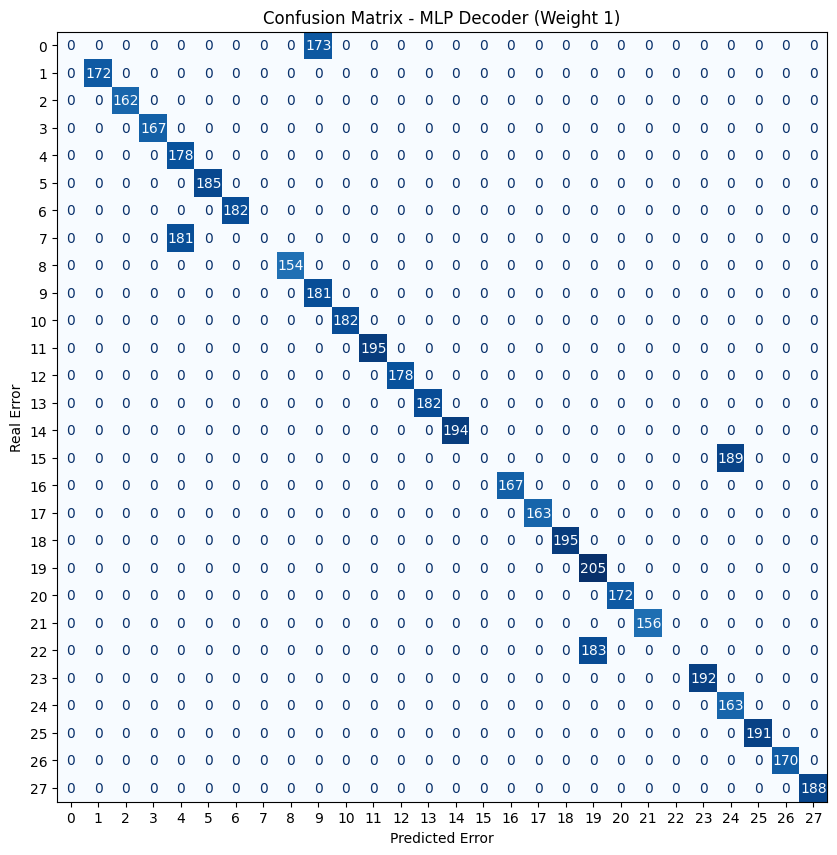

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred_mlp_np)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)
plt.title("Confusion Matrix - MLP Decoder (Weight 1)")
plt.xlabel("Predicted Error")
plt.ylabel("Real Error")
plt.show()

---

## 5.3 Test of the model for weight 1 + weight 2, the limit as $d=3$

In [70]:
data_test_2 = load_dataset(samples=5000, weight=2)

Dataset successfully loaded from datasets/surface_code_samples_5000_error_weight_2.pt


---

# 6. Model 2 based on Weight 1 + Weight 2.

## 6.1 init model

In [71]:
possible_errors_2 = generate_possible_errors(weight=2)
num_classes_2 = len(possible_errors_2)

print("Number of possible errors:", num_classes_2)

Number of possible errors: 352


Unlike before, there are many more possible (different) errors, 352 in this case, so in a dataset of 10,000 samples, that would mean the same error occurs 28 times on average, which is very few compared to the time it takes to generate our dataset.

We can therefore use a dataset of 20,000 samples, which will result in the same error occurring 57 times.

In [72]:
data_train_2 = load_dataset(samples=20000, weight=2)

Dataset successfully loaded from datasets/surface_code_samples_20000_error_weight_2.pt


In [73]:
model_2 = SurfaceCodeDecoderMLP(input_dim=8, hidden_dim=128, output_dim=num_classes_2)

In [74]:
model_2 = training(model_2, data_train_2, num_epochs=15)

Start of model training
Epoch [1/15] | Loss: 2.0167 | Accuracy: 36.31%
Epoch [2/15] | Loss: 1.2569 | Accuracy: 40.81%
Epoch [3/15] | Loss: 1.1967 | Accuracy: 41.48%
Epoch [4/15] | Loss: 1.1701 | Accuracy: 41.45%
Epoch [5/15] | Loss: 1.1471 | Accuracy: 41.79%
Epoch [6/15] | Loss: 1.1339 | Accuracy: 41.66%
Epoch [7/15] | Loss: 1.1231 | Accuracy: 41.36%
Epoch [8/15] | Loss: 1.1182 | Accuracy: 41.33%
Epoch [9/15] | Loss: 1.1141 | Accuracy: 40.91%
Epoch [10/15] | Loss: 1.1044 | Accuracy: 41.35%
Epoch [11/15] | Loss: 1.1024 | Accuracy: 41.52%
Epoch [12/15] | Loss: 1.0982 | Accuracy: 41.64%
Epoch [13/15] | Loss: 1.0941 | Accuracy: 41.37%
Epoch [14/15] | Loss: 1.0929 | Accuracy: 41.27%
Epoch [15/15] | Loss: 1.0881 | Accuracy: 41.48%
Complete


---

## 6.2 Comparison of LUT vs. MLP on Weight 1


---

## 6.3 Test of the model for weight 1 + weight 2

---

# References

- **Machine Learning for Physics** (2025-2026)
  Midlands Physics Alliance Graduate School (MPAGS): Course Module, Access: [https://warwick.ac.uk/fac/sci/physics/mpags/modules/comp/machinelearning/25-26/](https://warwick.ac.uk/fac/sci/physics/mpags/modules/comp/machinelearning/25-26/)

- **PyTorch documentation** https://docs.pytorch.org/docs/main/
  